# B14 用户只评价过少量电影，怎样推荐？

在模拟评分中按用户留出后续评价，构造用户—电影矩阵并做物品协同过滤。与平均评分推荐比较，检查已看过过滤、冷启动与评测偏差。

先修：B11—B13；矩阵、余弦相似度、缺失占位、排序与离线评测。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 评分是部分观察，不是完整偏好
模拟 60 位用户对 15 部电影的部分评分，三类口味构成隐含结构。每人 8 次评分，最后两次留出。未评分不是零分；0 只能用作矩阵缺失占位。

In [2]:
import numpy as np,pandas as pd,json
from sklearn.metrics.pairwise import cosine_similarity
rng = np.random.default_rng(14); n_users,n_items = 60,15
records=[]
for user in range(n_users):
    taste = user%3
    chosen = rng.choice(n_items,8,replace=False)
    for event,item in enumerate(chosen):
        rating = np.clip(2.8 + 1.8*(item%3==taste) + rng.normal(0,0.45),1,5)
        records.append((user,int(item),event,float(rating)))
ratings = pd.DataFrame(records,columns=['user','item','event','rating'])
train = ratings.loc[ratings['event']<6].copy(); test = ratings.loc[ratings['event']>=6].copy()
matrix = train.pivot(index='user',columns='item',values='rating').reindex(index=range(n_users),columns=range(n_items))
ratings.to_csv(DATA_DIR/'simulated_ratings.csv',index=False)


## 2. 从训练评分学习电影相似度
先减去每位用户的均分，再把缺失填 0。对转置后的电影向量计算余弦相似度，并去掉自相似；只保留正相关使加权解释简单。不能使用留出评分算相似度。

In [3]:
user_means = matrix.mean(axis=1)
residual = matrix.sub(user_means,axis=0).fillna(0)
similarity = np.maximum(cosine_similarity(residual.T),0)
np.fill_diagonal(similarity,0)
popularity = matrix.mean(axis=0).fillna(train['rating'].mean()).to_numpy()


## 3. 为未看过的电影排序
候选电影分数来自已评分电影的相似度加权残差；无相似邻居时回退均分。已看过项目设为负无穷。新用户没有协同信号，只能先用全局候选。

In [4]:
def recommend(user, k=3, collaborative=True):
    if user not in matrix.index:
        return np.argsort(-popularity)[:k]
    seen = matrix.loc[user].notna().to_numpy()
    if collaborative:
        numerator = similarity @ residual.loc[user].to_numpy()
        denominator = similarity @ seen.astype(float)
        scores = float(user_means.loc[user]) + np.divide(numerator,denominator,out=np.zeros(n_items),where=denominator>0)
    else:
        scores = popularity.copy()
    scores[seen] = -np.inf
    return np.argsort(-scores)[:k]
assert not set(recommend(0)).intersection(set(train.loc[train['user']==0,'item']))


## 4. 留出正反馈命中率
仅对至少有一条留出评分≥4 的用户计算 Hit@3。未评分电影不应被当成确定负例；这是一份受观察偏差影响的离线评测，不能直接等同点击率提升。

In [5]:
evaluation=[]
for user,part in test.groupby('user'):
    positives=set(part.loc[part['rating']>=4,'item'])
    if not positives: continue
    cf=recommend(user); popular=recommend(user,collaborative=False)
    evaluation.append({'user':int(user),'cf_hit':int(bool(set(cf)&positives)),'popular_hit':int(bool(set(popular)&positives)),'recommendations':','.join(map(str,cf))})
evaluation=pd.DataFrame(evaluation)
metrics={'eligible_users':len(evaluation),'cf_hit_at_3':float(evaluation['cf_hit'].mean()),'popular_hit_at_3':float(evaluation['popular_hit'].mean())}
evaluation.to_csv(OUT_DIR/'recommendations.csv',index=False)
(OUT_DIR/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
plt.imshow(similarity,cmap='Blues'); plt.colorbar(label='电影相似度'); plt.xlabel('电影编号'); plt.ylabel('电影编号'); plt.tight_layout(); plt.savefig(OUT_DIR/'item_similarity.png'); plt.close(); print(metrics)


{'eligible_users': 34, 'cf_hit_at_3': 0.9411764705882353, 'popular_hit_at_3': 0.4117647058823529}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

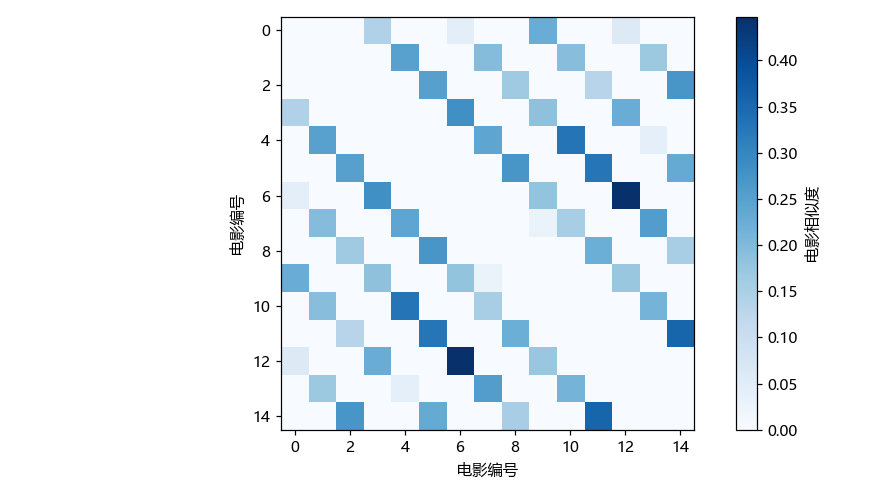

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
模拟评分不是真实电影偏好。用户留出法没有模拟全平台统一时间，生产评估应进一步按真实事件时间回放；此处只演示防止同一用户—电影泄漏。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。